results
                            OLS Regression Results                            
Dep. Variable:                    MPG   R-squared:                       0.886
Model:                            OLS   Adj. R-squared:                  0.880
Method:                 Least Squares   F-statistic:                     137.0
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           5.79e-40
Time:                        02:48:19   Log-Likelihood:                -226.64
No. Observations:                  94   AIC:                             465.3
Df Residuals:                      88   BIC:                             480.5
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         37.3993      2.147     17.423 

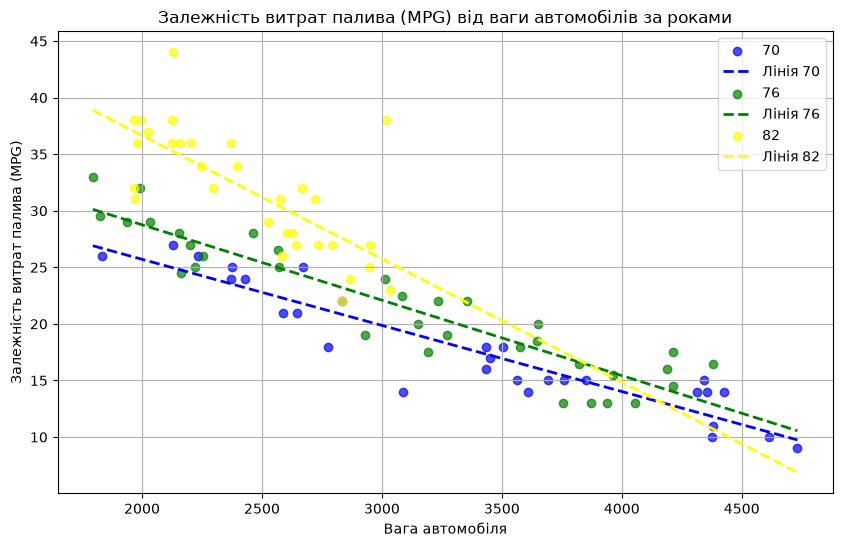

In [15]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

df = pd.read_csv('carsmall (1).csv')

df_clean = df.dropna(subset=['MPG', 'Weight']).copy()

df_clean['d_76'] = (df_clean['Model_Year'] == 76).astype(int)
df_clean['d_82'] = (df_clean['Model_Year'] == 82).astype(int)

df_clean['Weight_d76'] = df_clean['Weight'] * df_clean['d_76']
df_clean['Weight_d82'] = df_clean['Weight'] * df_clean['d_82']

X = sm.add_constant(df_clean[['Weight', 'd_76', 'd_82', 'Weight_d76', 'Weight_d82']])
y = df_clean['MPG']

model = sm.OLS(y, X).fit()

print("results")
print(model.summary())

b = model.params
print("\n" + "="*40)
print("Окремі моделі для кожної категорії:")
print(f"Year = 70: Y = {b.iloc[0]:.3f} + {b.iloc[1]:.3f} * X")
print(f"Year = 76: Y = {b.iloc[0]+b.iloc[2]:.3f} + {b.iloc[1]+b.iloc[4]:.3f} * X")
print(f"Year = 82: Y = {b.iloc[0]+b.iloc[3]:.3f} + {b.iloc[1]+b.iloc[5]:.3f} * X")
print("="*40 + "\n")

plt.figure(figsize=(10, 6))

colors = {70: 'blue', 76: 'green', 82: 'yellow'}
labels = {70: '70', 76: '76', 82: '82'}

x_line = np.linspace(df_clean['Weight'].min(), df_clean['Weight'].max(), 100)

for year in [70, 76, 82]: 
   subset = df_clean[df_clean['Model_Year'] == year] 
   plt.scatter(subset['Weight'], subset['MPG'], color=colors[year], label=labels[year], alpha=0.7)
   if year == 70:
      y_line = b.iloc[0] + b.iloc[1] * x_line
   elif year == 76:
      y_line = (b.iloc[0] + b.iloc[2]) + (b.iloc[1] + b.iloc[4]) * x_line
   elif year == 82:
      y_line = (b.iloc[0] +b.iloc[3]) + (b.iloc[1] + b.iloc[5]) * x_line
   plt.plot(x_line, y_line, color=colors[year], linestyle='--', linewidth=2, label=f'Лінія {year}')

plt.title('Залежність витрат палива (MPG) від ваги автомобілів за роками')
plt.xlabel('Вага автомобіля')
plt.ylabel('Залежність витрат палива (MPG)')
plt.legend()
plt.grid(True)
plt.show()